In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.gridding import create_mesh
from km5c.masks import apply_atlantic_mask_2d
from km5c.plotting import latdepthplot
from km5c.paths import FIG_DIR, GEBCO_PATH
from km5c.models import load_icesm12
from km5c.proxies import comparison_tables

icesm12 = load_icesm12()
Plio_d18O = icesm12.Plio_d18O
Plio_depth = icesm12.Plio_depth
Plio_lat = icesm12.Plio_lat
Plio_lon = icesm12.Plio_lon

proxy = comparison_tables()
PLIOMIP1_d13C = proxy.PLIOMIP1_d13C
PLIOMIP1_d18O = proxy.PLIOMIP1_d18O
PLIOMIP2_d13C_comparison_table = proxy.PLIOMIP2_d13C_comparison_table
PLIOMIP2_d18O_comparison_table = proxy.PLIOMIP2_d18O_comparison_table

4320
(4320,)
(4320,)


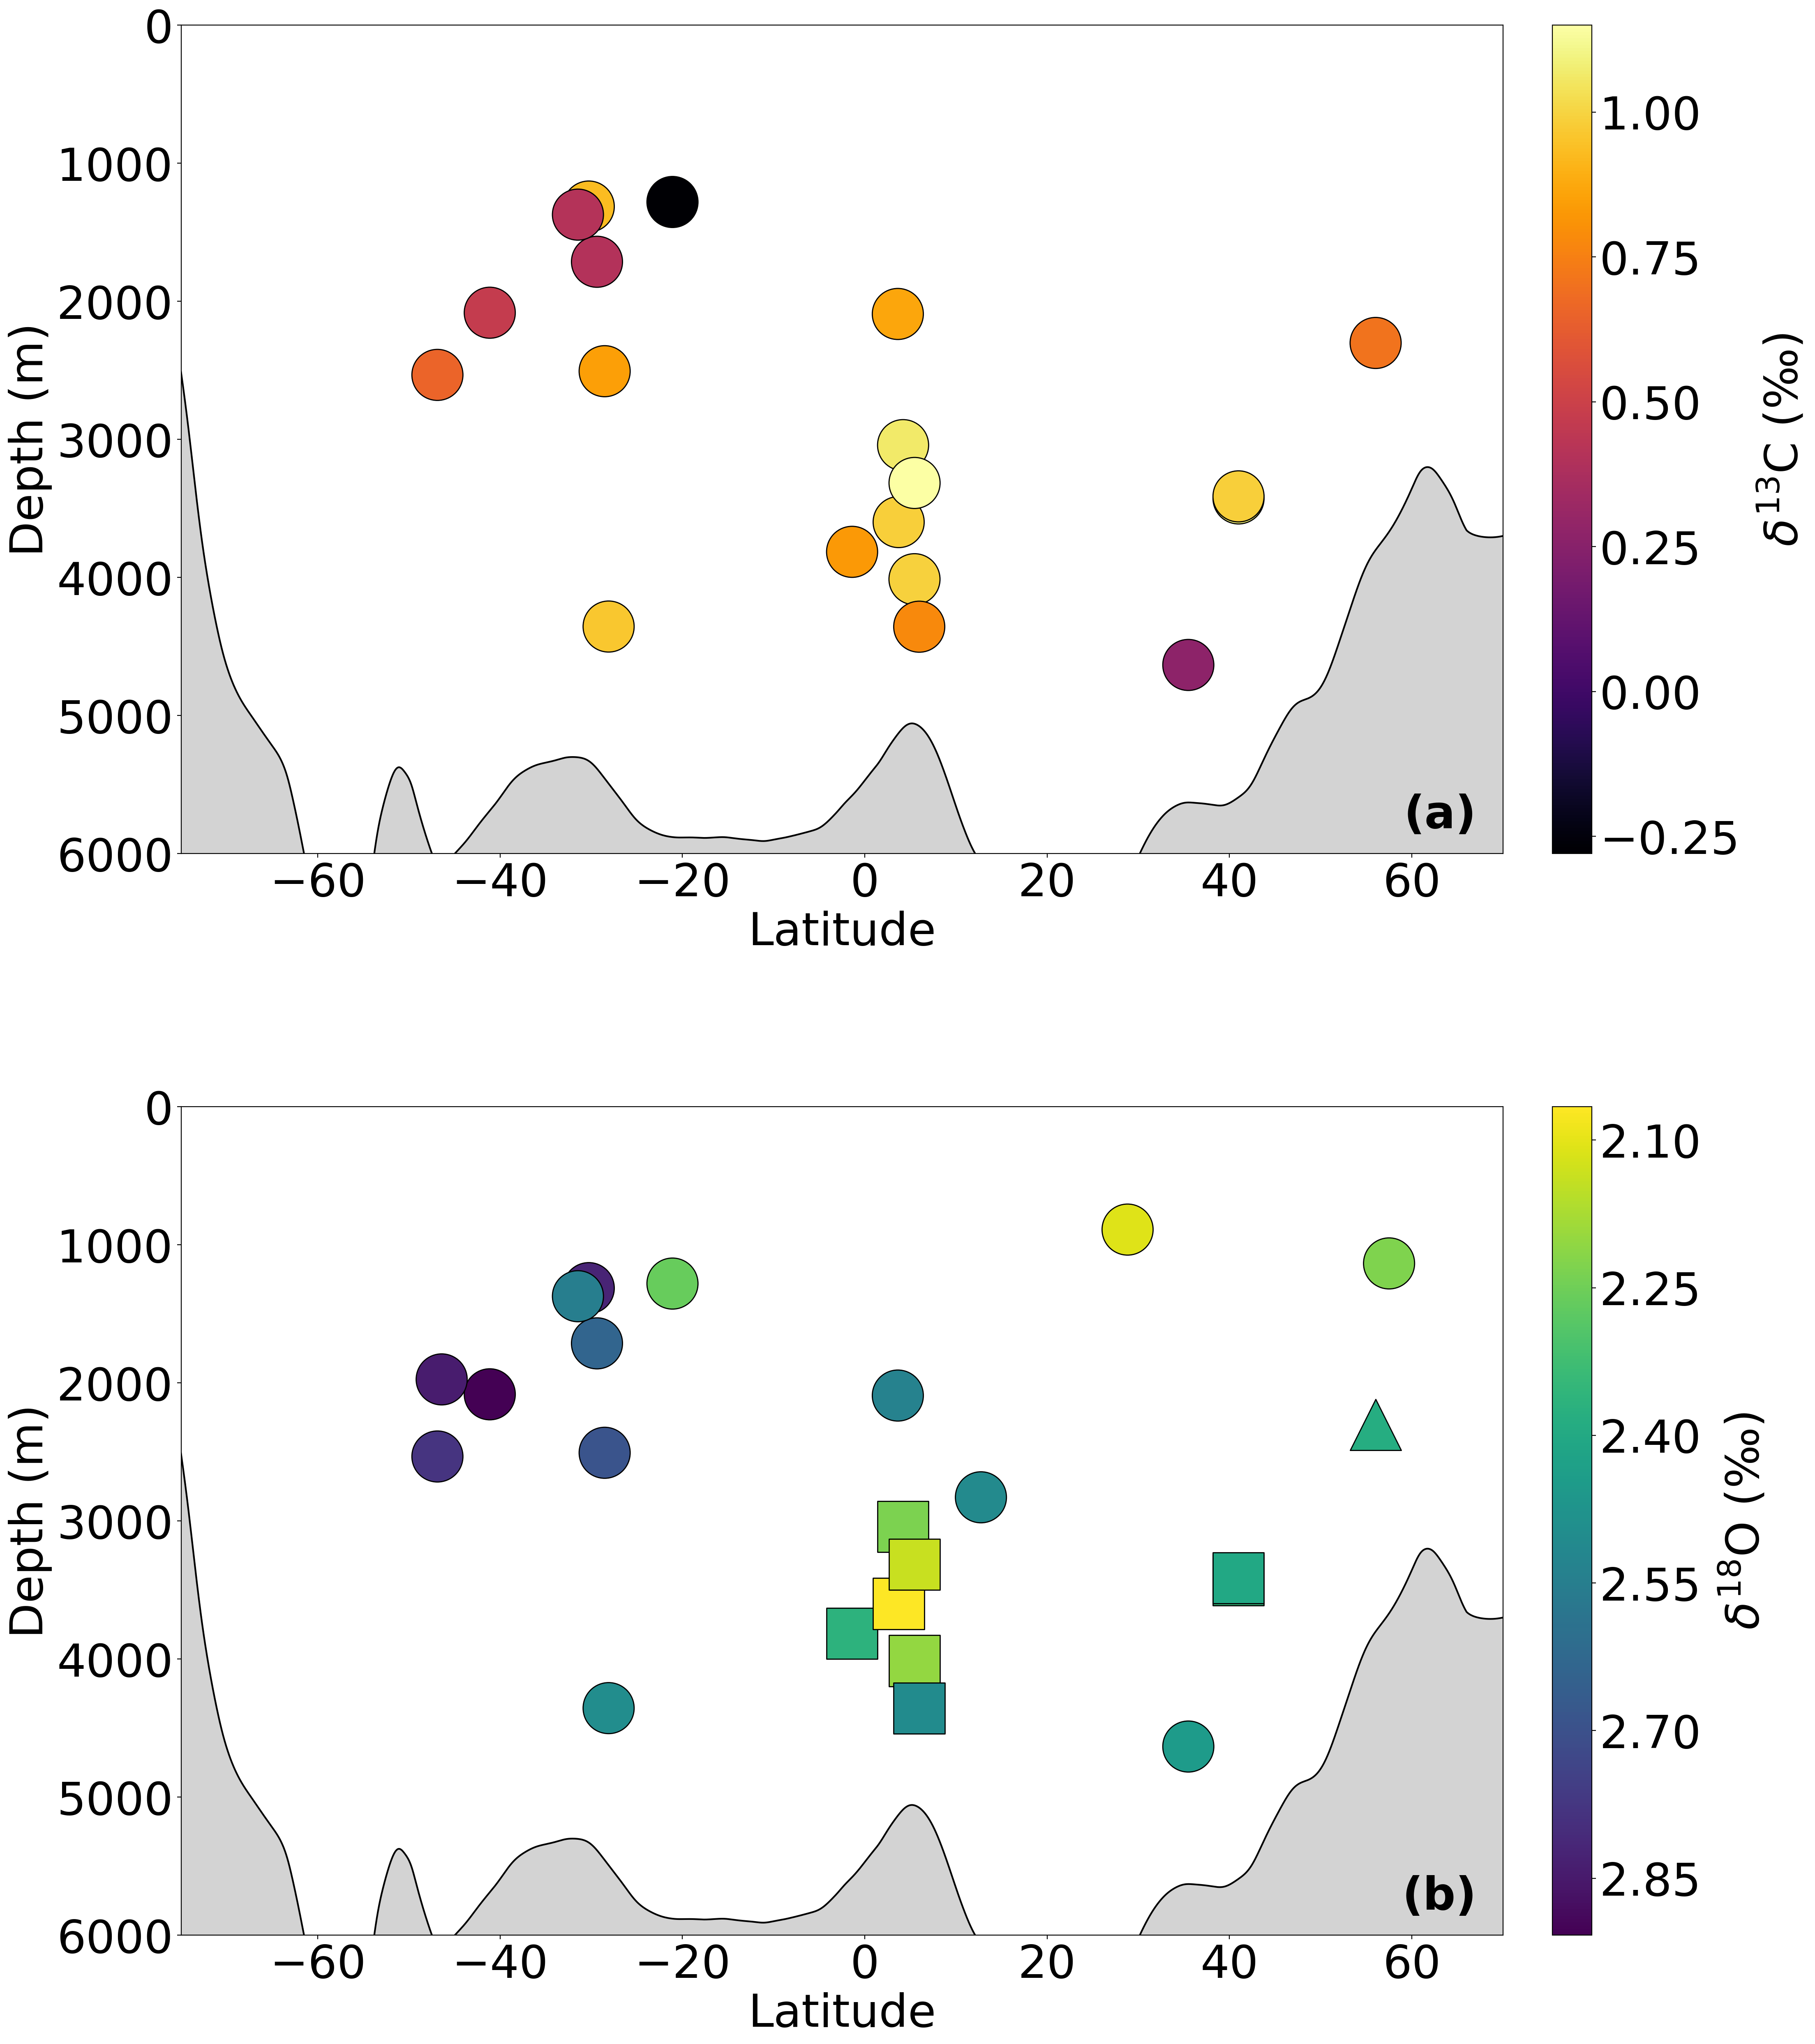

In [2]:
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 40,
    "axes.labelsize": 40,
    "xtick.labelsize": 40,
    "ytick.labelsize": 40,
})

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from statsmodels.nonparametric.smoothers_lowess import lowess

from collections import defaultdict

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr
from adjustText import adjust_text
from statsmodels.nonparametric.smoothers_lowess import lowess

def marker_from_taxa(taxa_value):
    s = str(taxa_value)
    has_c = "Cibicidoides" in s
    has_u = "Uvigerina" in s
    has_h = "Hydroides" in s
    # all three taxa
    if has_c and has_u and has_h:
        return "^"
    # mixed taxa including Cibicidoides + one of the others
    if has_c and (has_u or has_h):
        return "s"
    return "o"

# Bathymetry profile used in both panels
bathymetry_file_path = GEBCO_PATH
bathymetry = xr.open_dataset(bathymetry_file_path, chunks={"lat": 1000, "lon": 1000})
if float(bathymetry["lon"].max()) > 180:
    bathymetry = bathymetry.assign_coords(lon=(((bathymetry["lon"] + 180) % 360) - 180))
    bathymetry = bathymetry.sortby("lon")

# Subset and coarsen before loading into memory (full global grid is ~1+ GiB)
bathymetry_atl = bathymetry.sel(lat=slice(-90, 90), lon=slice(-100, 45))
bathymetry_downsampled = bathymetry_atl.coarsen(lat=10, lon=10, boundary="trim").mean()

bathymetry_lat = np.asarray(bathymetry_downsampled["lat"].values, dtype=float)
bathymetry_depth = bathymetry_downsampled["elevation"].astype(np.float32).compute().values
bathymetry_lon = np.asarray(bathymetry_downsampled["lon"].values, dtype=float)
bathymetry.close()
bathymetry_lat_mesh, bathymetry_lon_mesh = create_mesh(bathymetry_lat, bathymetry_lon)
# plus the function bodies for create_mesh + apply_atlantic_mask_2d
# Avoid notebook-local helpers by computing a simple lat-min bathymetry profile
bathymetry_depth_ocean = np.where(bathymetry_depth > 0, np.nan, bathymetry_depth)
compressed_bathymetry = np.nanmin(bathymetry_depth_ocean, axis=1)
compressed_bathymetry_positive = np.abs(compressed_bathymetry)

masked_bathymetry = apply_atlantic_mask_2d(bathymetry_depth, bathymetry_lat_mesh, bathymetry_lon_mesh)
masked_bathymetry = np.ma.masked_where(masked_bathymetry > 0, masked_bathymetry)
masked_bathymetry = masked_bathymetry.filled(np.nan)
# --- Full-latitude strict-min profile (for smoothed_full) ---
compressed_bathymetry_full = np.nanmin(masked_bathymetry, axis=1)
compressed_bathymetry_positive_full = np.abs(compressed_bathymetry_full)
# Example data
testplot, lat, depth = latdepthplot(Plio_lat, Plio_lon, Plio_depth, Plio_d18O, normalise=False)

# Stack the two panels with matching colorbars on the right
fig = plt.figure(figsize=(24, 28), dpi=200)
ax1 = fig.add_axes([0.12, 0.57, 0.67, 0.36])
cax1 = fig.add_axes([0.815, 0.57, 0.02, 0.36])
ax2 = fig.add_axes([0.12, 0.10, 0.67, 0.36])
cax2 = fig.add_axes([0.815, 0.10, 0.02, 0.36])
ax2.sharey(ax1)

# Plot for the first subplot (Top)
ax1.set_ylim(0, 6000)
ax1.set_xlim([-75, 70])
ax1.set_xlabel('Latitude', fontsize=40)
ax1.set_ylabel('Depth (m)', fontsize=40)
ax1.invert_yaxis()

pliomip_points = PLIOMIP2_d13C_comparison_table["PLIOMIP2 d13C"]
x = np.arange(len(compressed_bathymetry_positive_full))  # Indices or positions
y = np.array(compressed_bathymetry_positive_full)

print(len(compressed_bathymetry_positive_full)) 
print(np.shape(x))
print(np.shape(y))
# Apply Loess smoothing
frac = 0.05  # Fraction of data to use for smoothing (adjust as needed)
smoothed_full = lowess(y, x, frac=frac, return_sorted=False)
ax1.fill_between(bathymetry_lat, smoothed_full, 6000, color="lightgray", zorder=0)
ax1.plot(bathymetry_lat, smoothed_full, color='black', label="Bathymetry Depth")

norm1 = plt.Normalize(
    vmin=np.nanmin(pliomip_points),
    vmax=np.nanmax(pliomip_points)
)

scatter1 = ax1.scatter(
    PLIOMIP2_d13C_comparison_table["Latitude"],
    PLIOMIP2_d13C_comparison_table["Water depth (m)"],
    c=pliomip_points,
    cmap='inferno',
    norm=norm1,
    s=2000,
    marker='o',
    edgecolors='k'
)

# Plot for the second subplot (Bottom)
ax2.set_ylim(0, 6000)
ax2.set_xlim([-75, 70])
ax2.set_xlabel('Latitude', fontsize=40)
ax2.set_ylabel('Depth (m)', fontsize=40)
ax2.invert_yaxis()

right_df = PLIOMIP2_d18O_comparison_table.copy()

# Fallback to circles if taxons column is missing
if "taxons" in right_df.columns:
    right_markers = right_df["taxons"].apply(marker_from_taxa).fillna("o")
else:
    right_markers = np.array(["o"] * len(right_df))

norm2 = plt.Normalize(
    vmin=np.nanmin(right_df["PLIOMIP2 d18O"]),
    vmax=np.nanmax(right_df["PLIOMIP2 d18O"])
)

for mk in np.unique(right_markers):
    sel = (right_markers == mk)
    scatter2 = ax2.scatter(
        right_df.loc[sel, "Latitude"],
        right_df.loc[sel, "Water depth (m)"],
        c=right_df.loc[sel, "PLIOMIP2 d18O"],
        cmap="viridis_r",
        norm=norm2,
        s=2000,
        marker=mk,
        edgecolors="k"
    )

# Plot bathymetry in second subplot
ax2.fill_between(bathymetry_lat, smoothed_full, 6000, color="lightgray", zorder=0)
ax2.plot(bathymetry_lat, smoothed_full, color='black', label="Bathymetry Depth")



ax1.tick_params(axis='both', labelsize=40)
ax2.tick_params(axis='both', labelsize=40)
for ax, lab in zip([ax1, ax2], ["(a)", "(b)"]):
    ax.text(
        0.98, 0.02, lab,
        transform=ax.transAxes,
        ha="right", va="bottom",
        fontsize=40, fontweight="bold",
        zorder=20,
    )

# Add colorbar for the top plot (on the right)
cbar_ax1 = cax1
cbar1 = fig.colorbar(scatter1, cax=cbar_ax1)
cbar1.set_label(r'$\delta^{13}$C (‰)', fontsize=40, labelpad=16)

# Match the lower colorbar's right-side labels and ticks
cbar1.ax.yaxis.set_label_position('right')
cbar1.ax.yaxis.set_ticks_position('right')
cbar1.ax.tick_params(labelleft=False, labelright=True)

# Add colorbar for the bottom plot (on the right)
cbar_ax2 = cax2
cbar2 = fig.colorbar(scatter2, cax=cbar_ax2)
cbar2.set_label('$\delta^{18}$O (‰)', fontsize=40, labelpad=16)
cbar2.ax.invert_yaxis()  # Invert the colorbar axis

cbar1.ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=6))
cbar2.ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=6))
cbar1.ax.tick_params(labelsize=40)
cbar2.ax.tick_params(labelsize=40)

# No need for tight_layout as we're manually positioning everything
# plt.tight_layout(rect=[0, 0, 0.9, 1])

# Display the plot
fig.savefig(FIG_DIR / "proxies_KM5c_lat_depth.png", dpi=300, bbox_inches="tight")
plt.show()


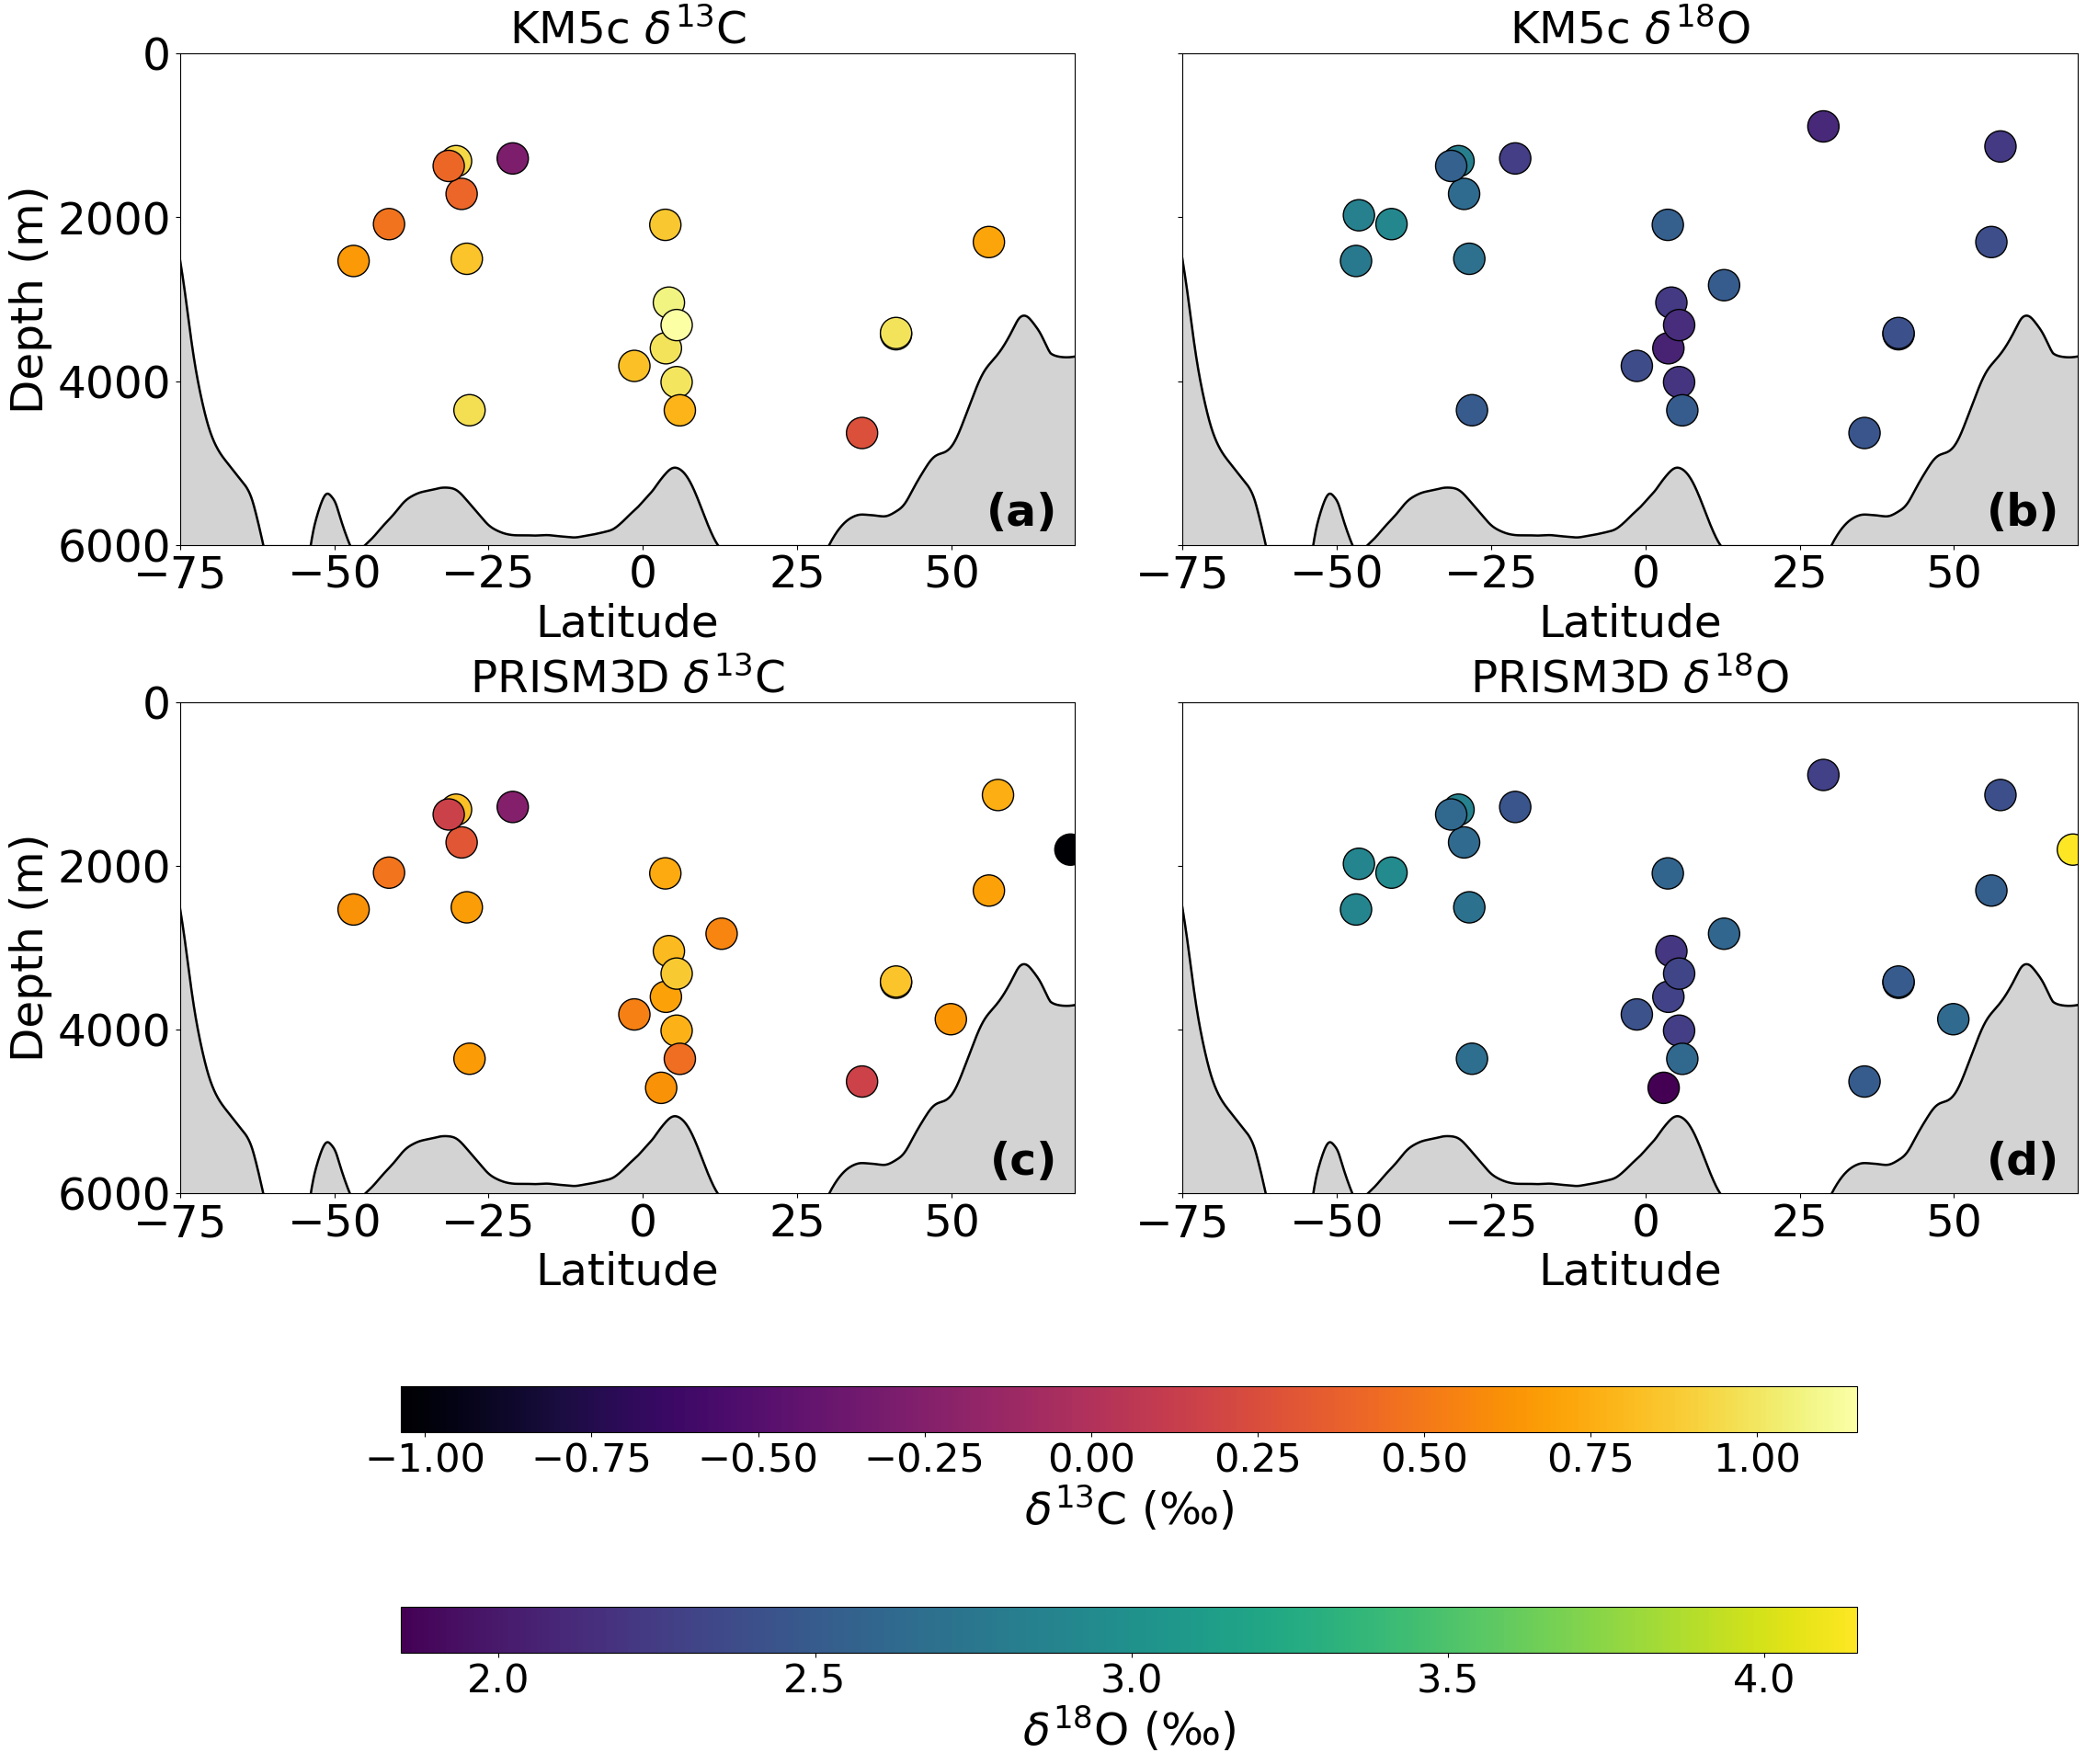

In [3]:
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 35,
    "axes.labelsize": 35,
    "xtick.labelsize": 35,
    "ytick.labelsize": 35,
})


# Find global min/max for d13C and d18O
d13C_all = np.concatenate([
    PLIOMIP2_d13C_comparison_table["PLIOMIP2 d13C"].values,
    PLIOMIP1_d13C["published d13C"].values
])
d18O_all = np.concatenate([
    PLIOMIP2_d18O_comparison_table["PLIOMIP2 d18O"].values,
    PLIOMIP1_d18O["published d18O"].values
])
d13C_vmin, d13C_vmax = np.min(d13C_all), np.max(d13C_all)
d18O_vmin, d18O_vmax = np.min(d18O_all), np.max(d18O_all)

lat_min, lat_max = -75, 70
depth_max = 6000

fig, ax = plt.subplots(2, 2, figsize=(24, 20), sharey=True)
plt.subplots_adjust(left=0.10, right=0.96, wspace=0.12, hspace=0.32, bottom=0.32, top=0.94)


def add_bathymetry_and_limits(axis):
    axis.fill_between(bathymetry_lat, smoothed_full, depth_max, color="lightgray", zorder=0)
    axis.plot(bathymetry_lat, smoothed_full, color="black", linewidth=1.8, zorder=1)
    axis.set_xlim(lat_min, lat_max)
    axis.set_ylim(0, depth_max)
    axis.invert_yaxis()


# --- Top Left: PLIOMIP2 d13C ---
add_bathymetry_and_limits(ax[0, 0])
scatter_00 = ax[0, 0].scatter(
    PLIOMIP2_d13C_comparison_table["Latitude"],
    PLIOMIP2_d13C_comparison_table["Water depth (m)"],
    c=PLIOMIP2_d13C_comparison_table["PLIOMIP2 d13C"],
    cmap='inferno',
    vmin=d13C_vmin, vmax=d13C_vmax,
    s=600, marker='o', edgecolors='k', zorder=3,
)
ax[0, 0].set_title('KM5c $\delta^{13}$C', fontsize=35)
ax[0, 0].set_xlabel('Latitude', fontsize=35)
ax[0, 0].set_ylabel('Depth (m)', fontsize=35)

# --- Top Right: PLIOMIP2 d18O ---
add_bathymetry_and_limits(ax[0, 1])
scatter_01 = ax[0, 1].scatter(
    PLIOMIP2_d18O_comparison_table["Latitude"],
    PLIOMIP2_d18O_comparison_table["Water depth (m)"],
    c=PLIOMIP2_d18O_comparison_table["PLIOMIP2 d18O"],
    cmap='viridis',
    vmin=d18O_vmin, vmax=d18O_vmax,
    s=600, marker='o', edgecolors='k', zorder=3,
)
ax[0, 1].set_title('KM5c $\delta^{18}$O', fontsize=35)
ax[0, 1].set_xlabel('Latitude', fontsize=35)

# --- Bottom Left: PLIOMIP1 d13C ---
add_bathymetry_and_limits(ax[1, 0])
scatter_10 = ax[1, 0].scatter(
    PLIOMIP1_d13C["lat"],
    PLIOMIP1_d13C["depth"],
    c=PLIOMIP1_d13C["published d13C"],
    cmap='inferno',
    vmin=d13C_vmin, vmax=d13C_vmax,
    s=600, marker='o', edgecolors='k', zorder=3,
)
ax[1, 0].set_title('PRISM3D $\delta^{13}$C', fontsize=35)
ax[1, 0].set_xlabel('Latitude', fontsize=35)
ax[1, 0].set_ylabel('Depth (m)', fontsize=35)

# --- Bottom Right: PLIOMIP1 d18O ---
add_bathymetry_and_limits(ax[1, 1])
scatter_11 = ax[1, 1].scatter(
    PLIOMIP1_d18O["lat"],
    PLIOMIP1_d18O["depth"],
    c=PLIOMIP1_d18O["published d18O"],
    cmap='viridis',
    vmin=d18O_vmin, vmax=d18O_vmax,
    s=600, marker='o', edgecolors='k', zorder=3,
)
ax[1, 1].set_title('PRISM3D $\delta^{18}$O', fontsize=35)
ax[1, 1].set_xlabel('Latitude', fontsize=35)

# --- Stack shared horizontal colorbars below the panels ---
# d13C colorbar (upper bar)
cbar_ax_d13C = fig.add_axes([0.20, 0.19, 0.66, 0.025])  # [left, bottom, width, height]
cbar_d13C = fig.colorbar(
    scatter_00, cax=cbar_ax_d13C, orientation='horizontal'
)
cbar_d13C.set_label('$\delta^{13}$C (‰)', fontsize=35)
cbar_d13C.ax.tick_params(labelsize=31)

# d18O colorbar (lower bar)
cbar_ax_d18O = fig.add_axes([0.20, 0.07, 0.66, 0.025])  # [left, bottom, width, height]
cbar_d18O = fig.colorbar(
    scatter_01, cax=cbar_ax_d18O, orientation='horizontal'
)
cbar_d18O.set_label('$\delta^{18}$O (‰)', fontsize=35)
cbar_d18O.ax.tick_params(labelsize=31)

for axis, label in zip([ax[0, 0], ax[0, 1], ax[1, 0], ax[1, 1]], ["(a)", "(b)", "(c)", "(d)"]):
    axis.text(
        0.98, 0.02, label,
        transform=axis.transAxes,
        ha="right", va="bottom",
        fontsize=35, fontweight="bold",
        zorder=20,
    )

fig.savefig(FIG_DIR / "proxies_PRISM3D_vs_KM5c.png", dpi=300, bbox_inches="tight")
plt.show()
